In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path

import cartopy
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import torch
from rasterio.enums import Resampling
from rasterio.merge import merge
from rasterio.warp import reproject
from scipy.ndimage import distance_transform_edt

import movebench.bench.run as bench_run
import movebench.bench.run_state as bench_run_state
import movebench.paths as paths
from movebench.bench.config import resolve_timescale
from movebench.bench.evaluation import runner as evaluation_runner
from movebench.geometry import (
    LOCAL_GEOMETRY,
    local_bounds_to_wgs84_parts,
    local_xy_m_from_lonlat,
)
from movebench.layers.io import LayerIO
from movebench.rasters import read_geotiff_window


In [2]:
REPO_ROOT = paths.repo_root()
os.chdir(REPO_ROOT)
RUNS_ROOT = REPO_ROOT / "results" / "bench" / "runs"
OUTPUT_DIR = REPO_ROOT / "visualizations"
STUDY_ROWS = [
    ("Accio_967b7813_raw_merged", "White stork"),
    #("BartlamBrooks_c9b4f9b5_raw_merged", "Plains zebra"), 
    # ("stabach2020_wildebeest", "Wildebeest"), 
    # ("killian_elephants", "African bush elephant"),
    # ("cagnacci_eurodeer_Alta_Val_di_Non_Cervus_elaphus", "Deer"),
    # ("gstsdttir_d4074e60_raw_merged", 'Reindeer')
    # ("Hebblewhite_fb867768_raw_merged", "Wolf")
    ("Morato_8fed4a87_raw_merged", "Jaguar")
]
TIMESCALE_ORDER = ["1h", "12h", "1d", "7d"]
RANDOM_SEED =  0 #8

WORLD_MAP_PATH = (
    Path(cartopy.config["repo_data_dir"])
    / "raster"
    / "natural_earth"
    / "50-natural-earth-1-downsampled.png"
)
WORLD_MAP_IMAGE = plt.imread(WORLD_MAP_PATH)
WORLD_MAP_EXTENT = (-180.0, 180.0, -90.0, 90.0)
PLATE_CARREE = ccrs.PlateCarree()
MAP_ROW_LANDSAT_ALPHA = 0.5
MAP_ROW_WATER_OVERLAY = False  # Show historical water extent in blue.
LANDSAT_MOSAIC_DAYS = 60  # Use cached imagery within this many days of the start.
_trajectory_points_cache: dict[str, pd.DataFrame] = {}
_support_rows_cache: dict[tuple[str, str, str], pd.DataFrame] = {}
_dem_rgba_cache: dict[
    tuple[str, str, int, str], tuple[np.ndarray, tuple[float, float, float, float]]
] = {}
_landsat_rgb_cache: dict[
    tuple[str, str, int, int], tuple[np.ndarray, tuple[float, float, float, float]]
] = {}

_water_rgba_cache: dict[
    tuple[str, str, int, str], tuple[np.ndarray, tuple[float, float, float, float]]
] = {}


In [3]:
METHOD_SPECS = [
    ("baseline_randomwalk", "CRW Baseline"),
    ("issf_linear", "iSSF"),
    ("issf_mlp", "iSSF MLP"),
    ("deepssf", "DeepSSF"),
    ("moveformer", "MoveFormer"),
]


RUN_SELECTION_MODE = "best_covariates" #"legacy_all" # "best_covariates"  # "legacy_all" or "best_covariates"
MAIN_EXPERIMENT_PATH = REPO_ROOT / "experiments" / "main_results.py"


def planned_run_map(study_ids: list[str]) -> dict[str, dict[str, object]]:
    planned_runs: dict[str, dict[str, object]] = {}
    experiment = bench_run.load_experiment(MAIN_EXPERIMENT_PATH)
    runs = bench_run.expand_experiment(
        experiment, studies_override=study_ids, readiness_map={}
    )
    for run in runs:
        run_payload = dict(run)
        planned_runs[str(run_payload["run_key"])] = run_payload

    return planned_runs


def completed_prediction_runs(*, study_ids: list[str]) -> dict[str, dict[str, object]]:
    planned_runs = planned_run_map(study_ids)
    latest_run_records = bench_run_state.search_latest_run_records_by_key(list(planned_runs.keys()))
    completed_runs: dict[str, dict[str, object]] = {}

    for run_key, run_payload in planned_runs.items():
        latest_run = dict(latest_run_records.get(run_key, {}))
        if (
            str(latest_run.get("status", "")) != "completed"
            or str(run_payload.get("method", "")) not in dict(METHOD_SPECS)
        ):
            continue
        completed_runs[run_key] = {
            "run_payload": run_payload,
            "latest_run": latest_run,
        }

    return completed_runs


def load_latest_legacy_runs(study_ids: list[str]) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    wanted_studies = set(study_ids)
    wanted_methods = {method for method, _ in METHOD_SPECS}
    for run_dir in sorted(RUNS_ROOT.iterdir()):
        if not run_dir.is_dir():
            continue
        resolved_path = run_dir / "resolved_run.json"
        pred_path = run_dir / "predictions" / "test_temporal.pt"
        summary_path = run_dir / "final_metrics" / "test_temporal" / "summary.json"
        if not resolved_path.exists() or not pred_path.exists() or not summary_path.exists():
            continue

        run_payload = json.loads(resolved_path.read_text())
        if run_payload.get("geometry") != LOCAL_GEOMETRY:
            continue
        if run_payload.get("study_id") not in wanted_studies:
            continue
        method = str(run_payload.get("method"))
        if method not in wanted_methods:
            continue
        if run_payload.get("covariate_set") != "all":
            continue

        completed_at = float(
            max(
                resolved_path.stat().st_mtime,
                pred_path.stat().st_mtime,
                summary_path.stat().st_mtime,
            )
        )
        rows.append(
            {
                "study_id": str(run_payload["study_id"]),
                "timescale": str(run_payload["timescale"]),
                "method": method,
                "run_dir": run_dir,
                "completed_at": completed_at,
            }
        )

    run_df = pd.DataFrame(rows)
    if run_df.empty:
        raise RuntimeError("No completed temporal prediction runs found.")
    return (
        run_df.sort_values("completed_at")
        .drop_duplicates(["study_id", "timescale", "method"], keep="last")
        .reset_index(drop=True)
    )


def load_latest_best_covariate_runs(study_ids: list[str]) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    wanted_methods = {method for method, _ in METHOD_SPECS}
    for run_key, payload in completed_prediction_runs(study_ids=study_ids).items():
        run_payload = dict(payload["run_payload"])
        latest_run = dict(payload["latest_run"])
        run_dir = RUNS_ROOT / run_key
        resolved_path = run_dir / "resolved_run.json"
        pred_path = run_dir / "predictions" / "test_temporal.pt"
        summary_path = run_dir / "final_metrics" / "test_temporal" / "summary.json"
        if not resolved_path.exists() or not pred_path.exists() or not summary_path.exists():
            continue

        method = str(run_payload.get("method"))
        timescale = str(run_payload.get("timescale"))
        if method not in wanted_methods:
            continue
        if timescale not in TIMESCALE_ORDER:
            continue

        end_time = latest_run.get("end_time")
        completed_at = (
            float(end_time) / 1000.0
            if isinstance(end_time, (int, float))
            else float(
                max(
                    resolved_path.stat().st_mtime,
                    pred_path.stat().st_mtime,
                    summary_path.stat().st_mtime,
                )
            )
        )
        rows.append(
            {
                "study_id": str(run_payload["study_id"]),
                "timescale": timescale,
                "method": method,
                "run_dir": run_dir,
                "completed_at": float(completed_at),
            }
        )

    run_df = pd.DataFrame(rows)
    if run_df.empty:
        raise RuntimeError("No completed temporal prediction runs found.")
    return (
        run_df.sort_values("completed_at")
        .drop_duplicates(["study_id", "timescale", "method"], keep="last")
        .reset_index(drop=True)
    )


def load_latest_runs(study_ids: list[str]) -> pd.DataFrame:
    if RUN_SELECTION_MODE == "legacy_all":
        return load_latest_legacy_runs(study_ids)
    if RUN_SELECTION_MODE == "best_covariates":
        return load_latest_best_covariate_runs(study_ids)
    raise ValueError(f"Unknown RUN_SELECTION_MODE: {RUN_SELECTION_MODE!r}")


def trajectory_points(study_id: str) -> pd.DataFrame:
    if study_id not in _trajectory_points_cache:
        trajectory_path = paths.study_dir(study_id) / "trajectories.csv"
        points_df = pd.read_csv(
            trajectory_path,
            usecols=[
                "point_id",
                "location-long",
                "location-lat",
                "timestamp",
                "individual-local-identifier",
            ],
        ).rename(
            columns={
                "location-long": "lon",
                "location-lat": "lat",
                "individual-local-identifier": "individual_id",
            }
        )
        points_df["point_id"] = points_df["point_id"].astype(int)
        _trajectory_points_cache[study_id] = points_df.set_index("point_id", drop=False)
    return _trajectory_points_cache[study_id]


def support_rows_for_run(run_row) -> pd.DataFrame:
    cache_key = (str(run_row.study_id), str(run_row.timescale), str(run_row.method))
    if cache_key not in _support_rows_cache:
        run_dir = Path(run_row.run_dir)
        run_payload = json.loads((run_dir / "resolved_run.json").read_text())
        selected_splits = evaluation_runner._selected_splits_for_split(
            run_payload=run_payload,
            split_key="test_temporal",
        )
        support_rows, _ = evaluation_runner._support_rows_for_split(
            study_id=str(run_row.study_id),
            split_key="test_temporal",
            timescale_key=str(run_row.timescale),
            selected_splits=selected_splits,
        )
        _support_rows_cache[cache_key] = pd.DataFrame(
            {
                "point_id_start": [int(row["point_id_start"]) for row in support_rows],
                "point_id_end": [int(row["point_id_end"]) for row in support_rows],
                "in_support": [bool(row["in_support"]) for row in support_rows],
            }
        )
    return _support_rows_cache[cache_key]


def choose_shared_start_point(run_rows: list[object], rng: np.random.Generator) -> int:
    point_sets = []
    in_support_sets = []
    for run_row in run_rows:
        support_df = support_rows_for_run(run_row)
        point_sets.append(set(support_df["point_id_start"].tolist()))
        in_support_sets.append(
            set(support_df.loc[support_df["in_support"], "point_id_start"].tolist())
        )

    if not point_sets:
        raise RuntimeError("choose_shared_start_point requires at least one run row")

    common_in_support = set.intersection(*in_support_sets) if in_support_sets else set()
    common_all = set.intersection(*point_sets)
    candidate_ids = sorted(common_in_support or common_all)
    if not candidate_ids:
        raise RuntimeError("No shared temporal test start point exists across requested runs")
    return int(candidate_ids[int(rng.integers(len(candidate_ids)))])


def grid_edges_local_m(
    pixel_size_m: float,
    shape: tuple[int, int],
) -> tuple[np.ndarray, np.ndarray]:
    height, width = shape
    x_offsets_m = (
        np.arange(width + 1, dtype=np.float64) - width / 2.0
    ) * float(pixel_size_m)
    y_offsets_m = (
        height / 2.0 - np.arange(height + 1, dtype=np.float64)
    ) * float(pixel_size_m)
    return np.meshgrid(x_offsets_m, y_offsets_m)


def chip_width_label(width_m: float) -> str:
    chip_width_km = float(np.round(float(width_m) / 1000.0))
    return f"{chip_width_km:g} km"


def energy_score_label(energy_score_m: float) -> str:
    if energy_score_m > 1000.0:
        return f"ES: {energy_score_m / 1000.0:,.1f}km"
    return f"ES: {energy_score_m:,.0f}m"


def panel_projection(panel: dict[str, object]):
    return ccrs.AzimuthalEquidistant(
        central_longitude=panel["start_lon"],
        central_latitude=panel["start_lat"],
        globe=ccrs.Globe(ellipse="WGS84"),
    )


def first_available_panel(study_panels: list[list[dict[str, object] | None]]) -> dict[str, object]:
    for timescale_panels in study_panels:
        for panel in timescale_panels:
            if panel is not None:
                return panel
    raise RuntimeError("Study is missing panels for the qualitative figure")


def first_available_timescale_panel(
    timescale_panels: list[dict[str, object] | None],
) -> dict[str, object] | None:
    for panel in timescale_panels:
        if panel is not None:
            return panel
    return None


def landsat_rgba_for_panel(
    panel: dict[str, object],
) -> tuple[np.ndarray, tuple[float, float, float, float]]:
    cache_key = (
        str(panel["study_id"]),
        str(panel["rasters_hash"]),
        int(panel["point_id_start"]),
        LANDSAT_MOSAIC_DAYS,
    )
    if cache_key not in _landsat_rgb_cache:
        raster_root = (
            paths.study_dir(str(panel["study_id"]))
            / "rasters"
            / str(panel["rasters_hash"])
        )
        meta = json.loads((raster_root / "chips_meta.json").read_text())
        band_ids = meta["chip_groups"]["high_res"]["band_ids_in_order"]
        rgb_indexes = [
            band_ids.index(f"landsat.{band}") + 1 for band in ["red", "green", "blue"]
        ]
        chip_path = (
            raster_root
            / "chips"
            / "high_res"
            / f"{int(panel['point_id_start']):05d}.tif"
        )
        with rasterio.open(chip_path) as ds:
            rgb_chw = ds.read(rgb_indexes).astype(np.float32)
            transform, crs = ds.transform, ds.crs
            extent = (
                float(ds.bounds.left),
                float(ds.bounds.right),
                float(ds.bounds.bottom),
                float(ds.bounds.top),
            )
        missing = ~(np.isfinite(rgb_chw) & (rgb_chw > -1000.0)).all(axis=0)
        if np.any(missing):
            mosaic_path = (
                REPO_ROOT
                / "results"
                / "visualizations"
                / "landsat_mosaics"
                / str(panel["study_id"])
                / str(panel["rasters_hash"])
                / f"{int(panel['point_id_start']):05d}_pm{LANDSAT_MOSAIC_DAYS}d.npz"
            )
            if mosaic_path.exists():
                with np.load(mosaic_path) as saved:
                    rgb_chw[:, missing] = saved["rgb"][:, missing]
            else:
                points = trajectory_points(str(panel["study_id"]))
                time_distance = (
                    pd.to_datetime(points["timestamp"])
                    - pd.Timestamp(panel["start_timestamp"])
                ).abs()
                width, height = extent[1] - extent[0], extent[3] - extent[2]
                nearby = (
                    time_distance.le(pd.Timedelta(days=LANDSAT_MOSAIC_DAYS))
                    & points["lon"].between(extent[0] - width / 2, extent[1] + width / 2)
                    & points["lat"].between(extent[2] - height / 2, extent[3] + height / 2)
                    & points["point_id"].ne(int(panel["point_id_start"]))
                )
                # Fill from the closest dates first, preserving existing RGB pixels.
                for point_id in time_distance[nearby].sort_values().index:
                    nearby_path = chip_path.parent / f"{int(point_id):05d}.tif"
                    if not nearby_path.exists():
                        continue
                    with rasterio.open(nearby_path) as ds:
                        values = ds.read(rgb_indexes).astype(np.float32)
                        valid_source = (
                            np.isfinite(values) & (values > -1000.0)
                        ).all(axis=0)
                        values[:, ~valid_source] = -9999.0
                        aligned = np.full_like(rgb_chw, -9999.0)
                        reproject(
                            values,
                            aligned,
                            src_transform=ds.transform,
                            src_crs=ds.crs,
                            dst_transform=transform,
                            dst_crs=crs,
                            src_nodata=-9999.0,
                            dst_nodata=-9999.0,
                            resampling=Resampling.nearest,
                        )
                    fill = missing & (
                        np.isfinite(aligned) & (aligned > -1000.0)
                    ).all(axis=0)
                    rgb_chw[:, fill] = aligned[:, fill]
                    missing[fill] = False
                    if not np.any(missing):
                        break
                mosaic_path.parent.mkdir(parents=True, exist_ok=True)
                np.savez_compressed(mosaic_path, rgb=rgb_chw)
        valid = np.isfinite(rgb_chw) & (rgb_chw > -1000.0)
        valid_px = valid.all(axis=0)
        rgba = np.zeros((*valid_px.shape, 4), dtype=np.float32)
        rgba[..., 3] = valid_px.astype(np.float32)
        rgb_hwc = np.moveaxis(rgb_chw, 0, -1)
        if np.any(valid_px):
            rgb_valid = rgb_hwc[valid_px]
            lo, hi = np.quantile(rgb_valid, [0.02, 0.98])
            scale = max(float(hi - lo), 1e-6)
            rgba[..., :3][valid_px] = np.clip(
                (rgb_valid - float(lo)) / scale,
                0.0,
                1.0,
            )
            rgba[..., :3] = np.power(rgba[..., :3], 0.85)
        _landsat_rgb_cache[cache_key] = (rgba, extent)
    return _landsat_rgb_cache[cache_key]


def panel_bounds_latlon(
    panel: dict[str, object],
) -> tuple[float, float, float, float]:
    return local_bounds_to_wgs84_parts(
        panel["start_lon"],
        panel["start_lat"],
        (
            panel["xlim_m"][0],
            panel["ylim_m"][0],
            panel["xlim_m"][1],
            panel["ylim_m"][1],
        ),
    )[0]


def water_rgba_for_panel(
    panel: dict[str, object],
) -> tuple[np.ndarray, tuple[float, float, float, float]]:
    cache_key = (
        str(panel["study_id"]),
        str(panel["rasters_hash"]),
        int(panel["point_id_start"]),
        str(panel["timescale"]),
    )
    if cache_key not in _water_rgba_cache:
        plan = resolve_timescale(
            str(panel["timescale"]), study_id=str(panel["study_id"])
        )["plan"]
        layer_io = LayerIO(paths.study_dir(str(panel["study_id"])), plan)
        water = layer_io.load_layer(
            "dist_water", bounds_latlon=panel_bounds_latlon(panel)
        )
        # Zero distance marks JRC's maximum observed water extent (1984–2021).
        rgba = np.zeros((*water.array.shape[1:], 4), dtype=np.float32)
        rgba[..., :3] = (0.22, 0.45, 0.62)
        rgba[..., 3] = (water.array[0] == 0).astype(np.float32) * 0.75
        left, bottom, right, top = water.bounds
        _water_rgba_cache[cache_key] = (rgba, (left, right, bottom, top))
    return _water_rgba_cache[cache_key]


def dem_rgba_for_panel(
    panel: dict[str, object],
) -> tuple[np.ndarray, tuple[float, float, float, float]]:
    cache_key = (
        str(panel["study_id"]),
        str(panel["rasters_hash"]),
        int(panel["point_id_start"]),
        str(panel["timescale"]),
    )
    if cache_key not in _dem_rgba_cache:
        bounds_latlon = panel_bounds_latlon(panel)
        tile_dir = (
            paths.study_dir(str(panel["study_id"]))
            / "rasters"
            / str(panel["rasters_hash"])
            / "tiles"
            / "dem"
        )
        tile_index = json.loads((tile_dir / "index.json").read_text())
        matches = []
        min_lon, min_lat, max_lon, max_lat = bounds_latlon
        for tile in tile_index.get("tiles", []):
            tile_bounds = tile.get("bounds", {})
            if (
                float(tile_bounds["min_lon"]) <= max_lon
                and float(tile_bounds["max_lon"]) >= min_lon
                and float(tile_bounds["min_lat"]) <= max_lat
                and float(tile_bounds["max_lat"]) >= min_lat
            ):
                matches.append(tile_dir / tile["file"])
        if not matches:
            raise FileNotFoundError(f"No DEM tiles overlap {bounds_latlon!r}")
        if len(matches) == 1:
            dem_raster = read_geotiff_window(
                matches[0],
                bounds_latlon,
                max_window_hw=(400, 400),
                resampling=Resampling.bilinear,
            )
            dem_array = dem_raster.array[0].astype(np.float32, copy=False)
        else:
            datasets = [rasterio.open(path) for path in matches]
            try:
                mosaic, _transform = merge(datasets, bounds=bounds_latlon)
                dem_array = mosaic[0].astype(np.float32, copy=False)
            finally:
                for ds in datasets:
                    ds.close()
        valid = np.isfinite(dem_array) & (dem_array > -9000.0)
        filled = dem_array.copy()
        fill_value = float(np.nanmedian(filled[valid])) if np.any(valid) else 0.0
        filled[~valid] = fill_value
        center_lat = 0.5 * (min_lat + max_lat)
        dy_m = max(111320.0 * (max_lat - min_lat) / max(filled.shape[0], 1), 1.0)
        dx_m = max(
            111320.0
            * np.cos(np.deg2rad(center_lat))
            * (max_lon - min_lon)
            / max(filled.shape[1], 1),
            1.0,
        )
        grad_y, grad_x = np.gradient(filled, dy_m, dx_m)
        slope = np.pi / 2.0 - np.arctan(np.hypot(grad_x, grad_y))
        aspect = np.arctan2(-grad_x, grad_y)
        azimuth = np.deg2rad(315.0)
        altitude = np.deg2rad(45.0)
        shade = (
            np.sin(altitude) * np.sin(slope)
            + np.cos(altitude) * np.cos(slope) * np.cos(azimuth - aspect)
        )
        shade = np.clip((shade + 1.0) / 2.0, 0.0, 1.0)
        elev_lo, elev_hi = np.quantile(filled[valid], [0.02, 0.98]) if np.any(valid) else (0.0, 1.0)
        elev_norm = np.clip((filled - float(elev_lo)) / max(float(elev_hi - elev_lo), 1e-6), 0.0, 1.0)
        dem_gray = np.clip(0.10 + 0.65 * shade + 0.25 * elev_norm, 0.0, 1.0)
        rgba = np.zeros((*filled.shape, 4), dtype=np.float32)
        rgba[..., :3][valid] = dem_gray[valid, None]
        ocean_mask = ~valid
        if np.any(ocean_mask):
            ocean_dist = distance_transform_edt(ocean_mask).astype(np.float32)
            ocean_scale = max(float(np.quantile(ocean_dist[ocean_mask], 0.95)), 1.0)
            ocean_norm = np.clip(ocean_dist / ocean_scale, 0.0, 1.0)
            ocean_rgb = np.stack(
                [
                    0.68 - 0.16 * ocean_norm,
                    0.76 - 0.13 * ocean_norm,
                    0.82 - 0.08 * ocean_norm,
                ],
                axis=-1,
            )
            rgba[..., :3][ocean_mask] = ocean_rgb[ocean_mask]
        rgba[..., 3] = 1.0
        extent = (min_lon, max_lon, min_lat, max_lat)
        _dem_rgba_cache[cache_key] = (rgba, extent)
    return _dem_rgba_cache[cache_key]


def study_title_lines(panel: dict[str, object]) -> tuple[str, str]:
    return (
        f"Start point ● ({panel['start_lat']:.2f}, {panel['start_lon']:.2f}, "
        f"{panel['start_timestamp']})",
        "End point ★ at different time horizons",
    )


_grid_spec_cache: dict[tuple[str, str], tuple[tuple[int, int], float]] = {}


def reference_grid_spec(study_id: str, timescale: str) -> tuple[tuple[int, int], float]:
    cache_key = (str(study_id), str(timescale))
    if cache_key not in _grid_spec_cache:
        for method, _method_label in METHOD_SPECS:
            run_row = run_lookup.get((cache_key[0], cache_key[1], method))
            if run_row is None:
                continue
            pred_payload = torch.load(
                Path(run_row.run_dir) / "predictions" / "test_temporal.pt",
                map_location="cpu",
            )
            if pred_payload.get("geometry") != LOCAL_GEOMETRY:
                continue
            if "scores" not in pred_payload:
                continue
            _grid_spec_cache[cache_key] = (
                tuple(int(v) for v in pred_payload["scores"].shape[1:]),
                float(pred_payload["pixel_size_m"]),
            )
            break
        else:
            raise RuntimeError(
                f"No grid prediction artifact found for {cache_key[0]} {cache_key[1]}"
            )
    return _grid_spec_cache[cache_key]


def legacy_discrete_logp_hw(
    pred_payload: dict[str, object],
    pred_index: int,
    shape: tuple[int, int],
    pixel_size_m: float,
) -> np.ndarray:
    height, width = shape
    coords_m = torch.as_tensor(pred_payload["coords_m"][pred_index], dtype=torch.float64).numpy()
    probs = torch.as_tensor(pred_payload["probs"][pred_index], dtype=torch.float64).numpy()
    total_mass = float(np.sum(probs))
    if not np.isfinite(total_mass) or total_mass <= 0.0:
        raise ValueError("Legacy discrete prediction artifact has non-positive probability mass")
    probs = probs / total_mass
    col_float = coords_m[:, 0] / float(pixel_size_m) + (width - 1) / 2.0
    row_float = (height - 1) / 2.0 - coords_m[:, 1] / float(pixel_size_m)
    row0 = np.floor(row_float).astype(np.int64)
    col0 = np.floor(col_float).astype(np.int64)
    row_w = row_float - row0
    col_w = col_float - col0
    probs_hw = np.zeros((height, width), dtype=np.float64)
    for drow, dcol, weight in [
        (0, 0, (1.0 - row_w) * (1.0 - col_w)),
        (0, 1, (1.0 - row_w) * col_w),
        (1, 0, row_w * (1.0 - col_w)),
        (1, 1, row_w * col_w),
    ]:
        rows = row0 + drow
        cols = col0 + dcol
        valid = (rows >= 0) & (rows < height) & (cols >= 0) & (cols < width)
        if np.any(valid):
            np.add.at(probs_hw, (rows[valid], cols[valid]), probs[valid] * weight[valid])
    in_window_mass = float(np.sum(probs_hw))
    if not np.isfinite(in_window_mass) or in_window_mass <= 0.0:
        raise ValueError("Legacy discrete prediction artifact has no support on the reference grid")
    probs_hw /= in_window_mass
    logp_hw = np.full((height, width), -np.inf, dtype=np.float64)
    positive = probs_hw > 0.0
    logp_hw[positive] = np.log(probs_hw[positive])
    return logp_hw


def build_panel(run_row, point_id_start: int) -> dict[str, object]:
    support_df = support_rows_for_run(run_row)
    picked = support_df.loc[support_df["point_id_start"] == int(point_id_start)]
    if len(picked) != 1:
        raise ValueError(
            f"{run_row.study_id} {run_row.timescale} missing shared start point {point_id_start}"
        )
    picked_row = picked.iloc[0]

    run_dir = Path(run_row.run_dir)
    run_payload = json.loads((run_dir / "resolved_run.json").read_text())
    pred_payload = torch.load(
        run_dir / "predictions" / "test_temporal.pt",
        map_location="cpu",
    )
    if run_payload.get("geometry") != LOCAL_GEOMETRY:
        raise ValueError("Run geometry does not match the current AEQD contract")
    if pred_payload.get("geometry") != LOCAL_GEOMETRY:
        raise ValueError("Prediction geometry does not match the current AEQD contract")
    pred_point_ids = pred_payload["point_id_start"].numpy().astype(np.int64)
    pred_match = np.flatnonzero(pred_point_ids == int(point_id_start))
    if pred_match.size != 1:
        raise ValueError(
            f"{run_dir.name} expected one prediction row for point_id_start={point_id_start}"
        )
    pred_index = int(pred_match[0])
    energy_scores = pd.read_csv(
        run_dir / "final_metrics" / "test_temporal" / "energy_by_step.csv.gz",
        usecols=["point_id_start", "energy_score"],
    )
    energy_score = energy_scores.loc[
        energy_scores["point_id_start"] == int(point_id_start), "energy_score"
    ].iloc[0]

    points_df = trajectory_points(str(run_row.study_id))
    start_row = points_df.loc[int(point_id_start)]
    end_row = points_df.loc[int(picked_row.point_id_end)]
    if "scores" in pred_payload:
        pixel_size_m = float(pred_payload["pixel_size_m"])
        logp_hw = torch.log_softmax(
            pred_payload["scores"][pred_index].reshape(-1),
            dim=0,
        ).reshape(pred_payload["scores"].shape[1:]).numpy()
    else:
        shape, pixel_size_m = reference_grid_spec(str(run_row.study_id), str(run_row.timescale))
        logp_hw = legacy_discrete_logp_hw(pred_payload, pred_index, shape, pixel_size_m)

    x_edges_m, y_edges_m = grid_edges_local_m(float(pixel_size_m), logp_hw.shape)
    xlim_m = (float(np.nanmin(x_edges_m)), float(np.nanmax(x_edges_m)))
    ylim_m = (float(np.nanmin(y_edges_m)), float(np.nanmax(y_edges_m)))
    end_x_m, end_y_m = local_xy_m_from_lonlat(
        float(start_row.lon),
        float(start_row.lat),
        float(end_row.lon),
        float(end_row.lat),
    )
    return {
        "study_id": str(run_row.study_id),
        "timescale": str(run_row.timescale),
        "rasters_hash": str(run_payload["rasters_hash"]),
        "point_id_start": int(point_id_start),
        "point_id_end": int(picked_row.point_id_end),
        "in_support": bool(picked_row.in_support),
        "energy_score": float(energy_score),
        "start_lon": float(start_row.lon),
        "start_lat": float(start_row.lat),
        "start_timestamp": str(start_row.timestamp),
        "individual_id": str(start_row.individual_id),
        "start_x_m": 0.0,
        "start_y_m": 0.0,
        "end_x_m": float(end_x_m),
        "end_y_m": float(end_y_m),
        "x_edges_m": x_edges_m,
        "y_edges_m": y_edges_m,
        "xlim_m": xlim_m,
        "ylim_m": ylim_m,
        "chip_width_m": float(logp_hw.shape[1]) * float(pixel_size_m),
        "logp_hw": logp_hw,
    }


latest_runs = load_latest_runs([study_id for study_id, _ in STUDY_ROWS])
run_lookup = {
    (str(row.study_id), str(row.timescale), str(row.method)): row
    for row in latest_runs.itertuples(index=False)
}
rng = np.random.default_rng(RANDOM_SEED)
panels: list[list[list[dict[str, object] | None]]] = []
for study_id, _species in STUDY_ROWS:
    study_run_rows = [
        run_lookup[(study_id, timescale, method)]
        for timescale in TIMESCALE_ORDER
        for method, _method_label in METHOD_SPECS
        if (study_id, timescale, method) in run_lookup
    ]
    shared_point_id = choose_shared_start_point(study_run_rows, rng)
    row_panels: list[list[dict[str, object] | None]] = []
    for timescale in TIMESCALE_ORDER:
        timescale_panels: list[dict[str, object] | None] = []
        for method, _method_label in METHOD_SPECS:
            run_row = run_lookup.get((study_id, timescale, method))
            timescale_panels.append(
                None if run_row is None else build_panel(run_row, shared_point_id)
            )
        row_panels.append(timescale_panels)
    panels.append(row_panels)

map_panels = [
    [first_available_timescale_panel(timescale_panels) for timescale_panels in study_panels]
    for study_panels in panels
]

study_title_panels = [
    first_available_panel(study_panels)
    for study_panels in panels
]

surfaces = [
    panel["logp_hw"]
    for study_panels in panels
    for timescale_panels in study_panels
    for panel in timescale_panels
    if panel is not None
]
stack = np.concatenate([surface[np.isfinite(surface)] for surface in surfaces])
vmin_logp, vmax_logp = np.quantile(stack, [0.01, 0.99]).tolist()

print(vmin_logp, vmax_logp)

-32.57802516937256 -6.592448153495796


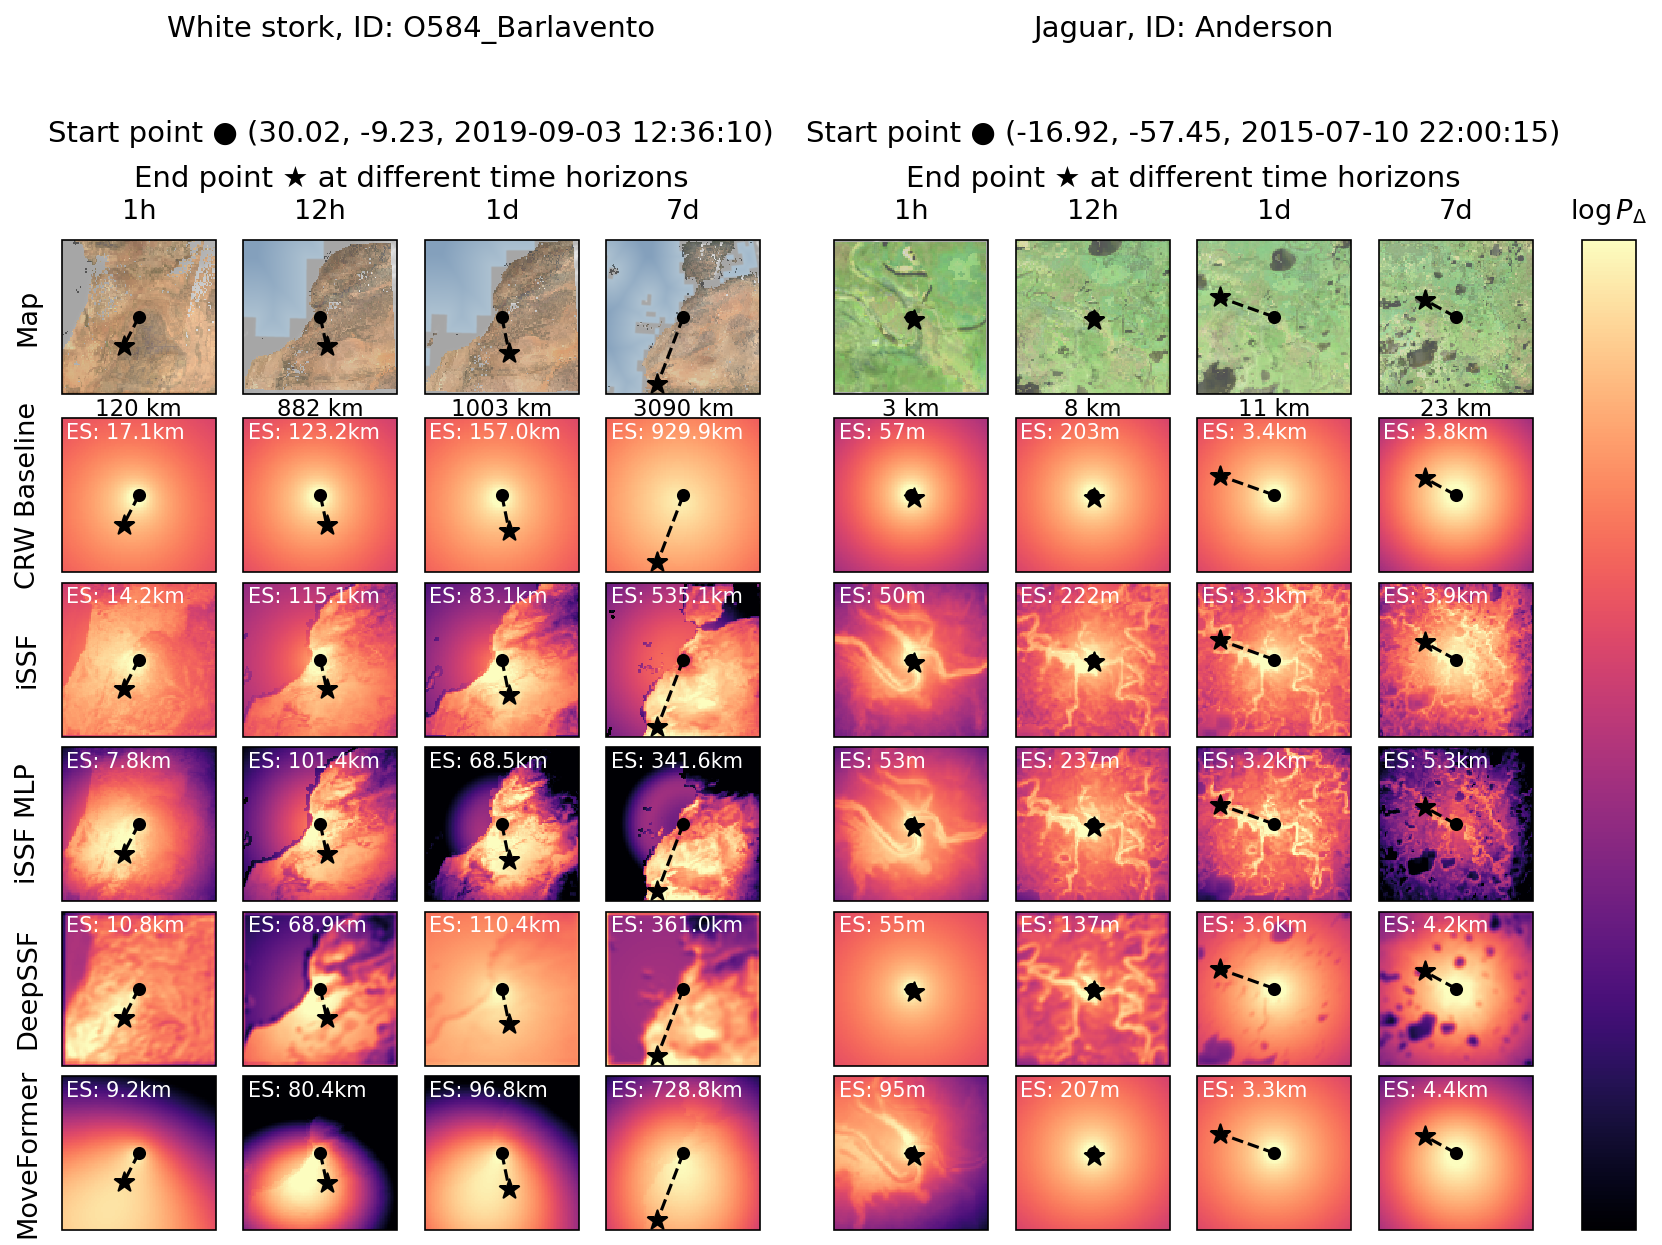

In [4]:
# Helps visualizations not look so washed out 
vmin_logp = -24


row_labels = ["Map"] + [method_label for _method, method_label in METHOD_SPECS]
fig = plt.figure(figsize=(11.5, 10))
plot_cols_per_study = len(TIMESCALE_ORDER)
plot_col_positions = [0, 1, 2, 3, 5, 6, 7, 8]
grid = fig.add_gridspec(
    len(row_labels) + 1,
    len(plot_col_positions) + 2,
    left=0.06,
    right=0.96,
    top=0.72,
    bottom=0.06,
    wspace=0.01,
    hspace=0.08,
    height_ratios=[1, 0.02] + [1] * (len(row_labels) - 1),
    width_ratios=[1, 1, 1, 1, 0.25, 1, 1, 1, 1, 0.3],
)
axes = np.empty((len(row_labels), len(plot_col_positions)), dtype=object)
color_mesh = None
for row_idx, row_label in enumerate(row_labels):
    is_map_row = row_idx == 0
    
    for study_idx, (_study_id, _species_name) in enumerate(STUDY_ROWS):
        for timescale_idx, _timescale in enumerate(TIMESCALE_ORDER):
            plot_col = study_idx * plot_cols_per_study + timescale_idx
            grid_row = row_idx if is_map_row else row_idx + 1
            panel = (
                map_panels[study_idx][timescale_idx]
                if is_map_row
                else panels[study_idx][timescale_idx][row_idx - 1]
            )
            ax = fig.add_subplot(
                grid[grid_row, plot_col_positions[plot_col]],
                projection=panel_projection(panel) if panel is not None else PLATE_CARREE,
            )
            axes[row_idx, plot_col] = ax
            if study_idx == 0 and timescale_idx == 0:
                ax.set_ylabel(row_label, fontsize=13, labelpad=10)

            if panel is None:
                ax.text(
                    0.5,
                    0.5,
                    "In progress",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                )
                ax.set_xticks([])
                ax.tick_params(axis="x", bottom=False, labelbottom=False, top=False)
                ax.set_yticks([])
                continue

            ax.set_xlim(*panel["xlim_m"])
            ax.set_ylim(*panel["ylim_m"])
            ax.set_aspect("equal")

            if is_map_row:
                dem_rgba, dem_extent = dem_rgba_for_panel(panel)
                ax.imshow(
                    dem_rgba,
                    extent=dem_extent,
                    transform=PLATE_CARREE,
                    interpolation="bicubic",
                    origin="upper",
                    zorder=0,
                )
                if MAP_ROW_LANDSAT_ALPHA > 0:
                    landsat_rgba, landsat_extent = landsat_rgba_for_panel(panel)
                    overlay_rgba = landsat_rgba.copy()
                    overlay_rgba[..., 3] *= float(MAP_ROW_LANDSAT_ALPHA)
                    ax.imshow(
                        overlay_rgba,
                        extent=landsat_extent,
                        transform=PLATE_CARREE,
                        interpolation="nearest",
                        origin="upper",
                        zorder=1,
                    )
                if MAP_ROW_WATER_OVERLAY:
                    water_rgba, water_extent = water_rgba_for_panel(panel)
                    ax.imshow(
                        water_rgba,
                        extent=water_extent,
                        transform=PLATE_CARREE,
                        interpolation="nearest",
                        origin="upper",
                        zorder=1.5,
                    )
                ax.set_facecolor("#d7e1e6")
            else:
                # ax.imshow(
                #     WORLD_MAP_IMAGE,
                #     extent=WORLD_MAP_EXTENT,
                #     transform=PLATE_CARREE,
                #     interpolation="bilinear",
                #     origin="upper",
                #     alpha=0.96,
                #     zorder=0,
                # )
                ax.set_facecolor("#eef2f3")
                color_mesh = ax.pcolormesh(
                    panel["x_edges_m"],
                    panel["y_edges_m"],
                    panel["logp_hw"],
                    shading="auto",
                    cmap="magma",
                    vmin=vmin_logp,
                    vmax=vmax_logp,
                    # alpha=0.5,
                    rasterized=True,
                    zorder=1,
                )
                ax.text(
                    0.03,
                    0.97,
                    energy_score_label(panel["energy_score"]),
                    color="white",
                    fontsize=10,
                    ha="left",
                    va="top",
                    transform=ax.transAxes,
                    zorder=5,
                )
            ax.plot(
                [panel["start_x_m"], panel["end_x_m"]],
                [panel["start_y_m"], panel["end_y_m"]],
                color="black",
                linewidth=1.5,
                linestyle="--",
                zorder=2,
            )
            ax.scatter(
                panel["start_x_m"],
                panel["start_y_m"],
                color="black",
                s=28,
                zorder=3,
            )
            ax.scatter(
                panel["end_x_m"],
                panel["end_y_m"],
                color="black",
                marker="*",
                s=95,
                zorder=4,
            )
            if is_map_row:
                x_center_m = 0.5 * (panel["xlim_m"][0] + panel["xlim_m"][1])
                ax.set_xticks([x_center_m])
                ax.set_xticklabels([chip_width_label(panel["chip_width_m"])], fontsize=11)
                ax.tick_params(
                    axis="x",
                    bottom=True,
                    labelbottom=True,
                    top=False,
                    length=0,
                    pad=2,
                )
            else:
                ax.set_xticks([])
                ax.tick_params(axis="x", bottom=False, labelbottom=False, top=False)
            ax.set_yticks([])

top_row_y = axes[0, 0].get_position().y1
study_species_y = 0.87
study_start_y = 0.80
study_end_y = 0.77
for plot_col in range(axes.shape[1]):
    top_ax = axes[0, plot_col]
    x_center = 0.5 * (top_ax.get_position().x0 + top_ax.get_position().x1)
    fig.text(
        x_center,
        top_row_y + 0.01,
        TIMESCALE_ORDER[plot_col % plot_cols_per_study],
        ha="center",
        va="bottom",
        fontsize=13,
    )

for study_idx, ((_study_id, species_name), panel) in enumerate(zip(STUDY_ROWS, study_title_panels)):
    left_col = study_idx * plot_cols_per_study
    right_col = left_col + plot_cols_per_study - 1
    left_ax = axes[0, left_col]
    right_ax = axes[0, right_col]
    x_center = 0.5 * (left_ax.get_position().x0 + right_ax.get_position().x1)
    fig.text(
        x_center,
        study_species_y,
        f"{species_name}, ID: {panel['individual_id']}",
        ha="center",
        va="top",
        fontsize=14,
    )
    start_line, end_line = study_title_lines(panel)
    for line_y, line_text in [(study_start_y, start_line), (study_end_y, end_line)]:
        fig.text(
            x_center, line_y, line_text,
            ha="center", va="top", fontsize=14,
        )

if color_mesh is not None:
    cax = fig.add_subplot(grid[:, 9])
    cax_pos = cax.get_position()
    cax.remove()
    cax = fig.add_axes([cax_pos.x0 + 0.02, cax_pos.y0, cax_pos.width, cax_pos.height])
    cbar = fig.colorbar(color_mesh, cax=cax)
    cbar.ax.set_title(r'$\log P_{\Delta}$', pad=10, fontsize=13)
    cbar.set_ticks([])
    cbar.ax.tick_params(length=0)

if MAP_ROW_WATER_OVERLAY:
    fig.text(
        0.06,
        0.015,
        "Water overlay: historical maximum extent (1984–2021). Source: EC JRC/Google.",
        fontsize=7,
        color="#444444",
        ha="left",
    )

plt.savefig(OUTPUT_DIR / f'qualitative_draft_v6_{RUN_SELECTION_MODE}_{RANDOM_SEED}_maptop.pdf',bbox_inches='tight',dpi=200)

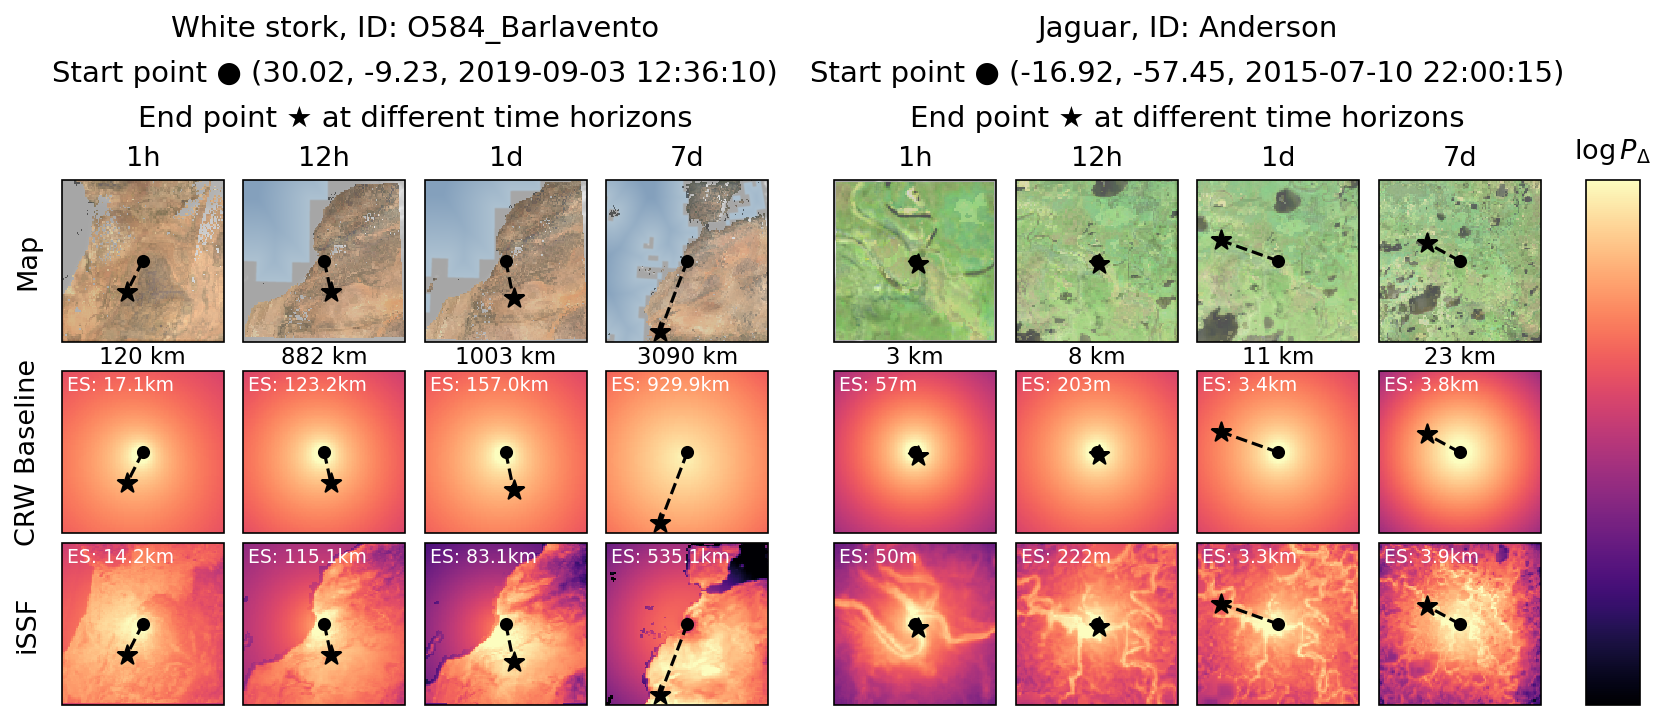

In [5]:
# Helps visualizations not look so washed out 
vmin_logp = -24


selected_method_names = {"baseline_randomwalk", "issf_linear" }#"deepssf"}
selected_method_specs = [
    (method, method_label)
    for method, method_label in METHOD_SPECS
    if method in selected_method_names
]
selected_method_indexes = [
    idx
    for idx, (method, _method_label) in enumerate(METHOD_SPECS)
    if method in selected_method_names
]
selected_panels = [
    [
        [timescale_panels[idx] for idx in selected_method_indexes]
        for timescale_panels in study_panels
    ]
    for study_panels in panels
]

row_labels = ["Map"] + [method_label for _method, method_label in selected_method_specs]
fig = plt.figure(figsize=(11.5, 5))
plot_cols_per_study = len(TIMESCALE_ORDER)
plot_col_positions = [0, 1, 2, 3, 5, 6, 7, 8]
grid = fig.add_gridspec(
    len(row_labels) + 1,
    len(plot_col_positions) + 2,
    left=0.06,
    right=0.96,
    top=0.76,
    bottom=0.06,
    wspace=0.01,
    hspace=0.08,
    height_ratios=[1, 0.06] + [1] * (len(row_labels) - 1),
    width_ratios=[1, 1, 1, 1, 0.25, 1, 1, 1, 1, 0.3],
)
axes = np.empty((len(row_labels), len(plot_col_positions)), dtype=object)
color_mesh = None
for row_idx, row_label in enumerate(row_labels):
    is_map_row = row_idx == 0
    
    for study_idx, (_study_id, _species_name) in enumerate(STUDY_ROWS):
        for timescale_idx, _timescale in enumerate(TIMESCALE_ORDER):
            plot_col = study_idx * plot_cols_per_study + timescale_idx
            grid_row = row_idx if is_map_row else row_idx + 1
            panel = (
                map_panels[study_idx][timescale_idx]
                if is_map_row
                else selected_panels[study_idx][timescale_idx][row_idx - 1]
            )
            ax = fig.add_subplot(
                grid[grid_row, plot_col_positions[plot_col]],
                projection=panel_projection(panel) if panel is not None else PLATE_CARREE,
            )
            axes[row_idx, plot_col] = ax
            if study_idx == 0 and timescale_idx == 0:
                ax.set_ylabel(row_label, fontsize=13, labelpad=10)

            if panel is None:
                ax.text(
                    0.5,
                    0.5,
                    "In progress",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                )
                ax.set_xticks([])
                ax.tick_params(axis="x", bottom=False, labelbottom=False, top=False)
                ax.set_yticks([])
                continue

            ax.set_xlim(*panel["xlim_m"])
            ax.set_ylim(*panel["ylim_m"])
            ax.set_aspect("equal")

            if is_map_row:
                dem_rgba, dem_extent = dem_rgba_for_panel(panel)
                ax.imshow(
                    dem_rgba,
                    extent=dem_extent,
                    transform=PLATE_CARREE,
                    interpolation="bicubic",
                    origin="upper",
                    zorder=0,
                )
                if MAP_ROW_LANDSAT_ALPHA > 0:
                    landsat_rgba, landsat_extent = landsat_rgba_for_panel(panel)
                    overlay_rgba = landsat_rgba.copy()
                    overlay_rgba[..., 3] *= float(MAP_ROW_LANDSAT_ALPHA)
                    ax.imshow(
                        overlay_rgba,
                        extent=landsat_extent,
                        transform=PLATE_CARREE,
                        interpolation="nearest",
                        origin="upper",
                        zorder=1,
                    )
                if MAP_ROW_WATER_OVERLAY:
                    water_rgba, water_extent = water_rgba_for_panel(panel)
                    ax.imshow(
                        water_rgba,
                        extent=water_extent,
                        transform=PLATE_CARREE,
                        interpolation="nearest",
                        origin="upper",
                        zorder=1.5,
                    )
                ax.set_facecolor("#d7e1e6")
            else:
                # ax.imshow(
                #     WORLD_MAP_IMAGE,
                #     extent=WORLD_MAP_EXTENT,
                #     transform=PLATE_CARREE,
                #     interpolation="bilinear",
                #     origin="upper",
                #     alpha=0.96,
                #     zorder=0,
                # )
                ax.set_facecolor("#eef2f3")
                color_mesh = ax.pcolormesh(
                    panel["x_edges_m"],
                    panel["y_edges_m"],
                    panel["logp_hw"],
                    shading="auto",
                    cmap="magma",
                    vmin=vmin_logp,
                    vmax=vmax_logp,
                    # alpha=0.5,
                    rasterized=True,
                    zorder=1,
                )
                ax.text(
                    0.03,
                    0.97,
                    energy_score_label(panel["energy_score"]),
                    color="white",
                    fontsize=9,
                    ha="left",
                    va="top",
                    transform=ax.transAxes,
                    zorder=5,
                )
            ax.plot(
                [panel["start_x_m"], panel["end_x_m"]],
                [panel["start_y_m"], panel["end_y_m"]],
                color="black",
                linewidth=1.5,
                linestyle="--",
                zorder=2,
            )
            ax.scatter(
                panel["start_x_m"],
                panel["start_y_m"],
                color="black",
                s=28,
                zorder=3,
            )
            ax.scatter(
                panel["end_x_m"],
                panel["end_y_m"],
                color="black",
                marker="*",
                s=95,
                zorder=4,
            )
            if is_map_row:
                x_center_m = 0.5 * (panel["xlim_m"][0] + panel["xlim_m"][1])
                ax.set_xticks([x_center_m])
                ax.set_xticklabels([chip_width_label(panel["chip_width_m"])], fontsize=11)
                ax.tick_params(
                    axis="x",
                    bottom=True,
                    labelbottom=True,
                    top=False,
                    length=0,
                    pad=2,
                )
            else:
                ax.set_xticks([])
                ax.tick_params(axis="x", bottom=False, labelbottom=False, top=False)
            ax.set_yticks([])

top_row_y = axes[0, 0].get_position().y1
study_species_y = 0.98
study_start_y = 0.92
study_end_y = 0.86
for plot_col in range(axes.shape[1]):
    top_ax = axes[0, plot_col]
    x_center = 0.5 * (top_ax.get_position().x0 + top_ax.get_position().x1)
    fig.text(
        x_center,
        top_row_y + 0.01,
        TIMESCALE_ORDER[plot_col % plot_cols_per_study],
        ha="center",
        va="bottom",
        fontsize=13,
    )

for study_idx, ((_study_id, species_name), panel) in enumerate(zip(STUDY_ROWS, study_title_panels)):
    left_col = study_idx * plot_cols_per_study
    right_col = left_col + plot_cols_per_study - 1
    left_ax = axes[0, left_col]
    right_ax = axes[0, right_col]
    x_center = 0.5 * (left_ax.get_position().x0 + right_ax.get_position().x1)
    fig.text(
        x_center,
        study_species_y,
        f"{species_name}, ID: {panel['individual_id']}",
        ha="center",
        va="top",
        fontsize=14,
    )
    start_line, end_line = study_title_lines(panel)
    for line_y, line_text in [(study_start_y, start_line), (study_end_y, end_line)]:
        fig.text(
            x_center, line_y, line_text,
            ha="center", va="top", fontsize=14,
        )

if color_mesh is not None:
    cax = fig.add_subplot(grid[:, 9])
    cax_pos = cax.get_position()
    cax.remove()
    cax = fig.add_axes([cax_pos.x0 + 0.02, cax_pos.y0, cax_pos.width, cax_pos.height])
    cbar = fig.colorbar(color_mesh, cax=cax)
    cbar.ax.set_title(r'$\log P_{\Delta}$', pad=10, fontsize=13)
    cbar.set_ticks([])
    cbar.ax.tick_params(length=0)

if MAP_ROW_WATER_OVERLAY:
    fig.text(
        0.06,
        0.015,
        "Water overlay: historical maximum extent (1984–2021). Source: EC JRC/Google.",
        fontsize=7,
        color="#444444",
        ha="left",
    )

plt.savefig(OUTPUT_DIR / f'qualitative_draft_v5_{RUN_SELECTION_MODE}_{RANDOM_SEED}_maptop_crw_issfl.pdf',bbox_inches='tight',dpi=200)